Phase 1: Data Preparation & Exploration (Tasks 1–3)

In [3]:
# ==========================================
# 1. LOAD AND CLEAN DATA (Task 1)
# ==========================================
# Point to your Colab file path
file_path = "/content/daily-minimum-temperatures-in-me.csv"

# Added on_bad_lines='skip' to automatically drop the footer metadata line
df = pd.read_csv(file_path, names=["Date", "Temp"], skiprows=1, on_bad_lines='skip')

# Clean '?' prefixes, handle anomalies, and convert to numeric
df['Temp'] = df['Temp'].astype(str).str.replace('?', '', regex=False)
df['Temp'] = pd.to_numeric(df['Temp'], errors='coerce')

# Convert Date to datetime and set as index
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date', 'Temp'])
df.set_index('Date', inplace=True)

# Ensure a continuous daily frequency and fill gaps using linear interpolation
series = df['Temp'].asfreq('D').interpolate()

print(f"Data successfully loaded! Total days in time series: {len(series)}")


Data successfully loaded! Total days in time series: 3652


2556 548 548
train: 1981-01-01 -> 1987-12-31
val:   1988-01-01 -> 1989-07-01
test:  1989-07-02 -> 1990-12-31
AR(1) [Test] RMSE=2.428 MAE=1.928 MAPE=21.9% sMAPE=19.2% R2=0.612


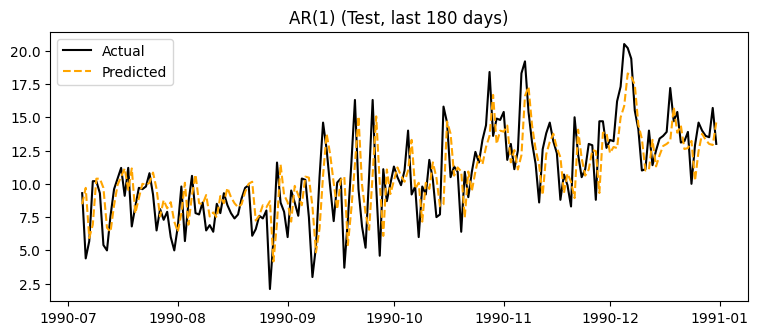

In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

n = len(series)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train, val, test = series.iloc[:train_end], series.iloc[train_end:val_end], series.iloc[val_end:]
print(len(train), len(val), len(test))
print("train:", train.index[0].date(), "->", train.index[-1].date())
print("val:  ", val.index[0].date(), "->", val.index[-1].date())
print("test: ", test.index[0].date(), "->", test.index[-1].date())

results = {}

def evaluate(actual, predicted, name, split="Test"):
    a = np.asarray(actual, float); p = np.asarray(predicted, float)
    rmse = np.sqrt(mean_squared_error(a, p))
    mae = mean_absolute_error(a, p)
    mape = np.mean(np.abs((a - p) / np.where(a == 0, 1e-5, a))) * 100
    smape = np.mean(2 * np.abs(a - p) / (np.abs(a) + np.abs(p) + 1e-9)) * 100
    r2 = r2_score(a, p)
    results[(name, split)] = dict(RMSE=rmse, MAE=mae, MAPE=mape, sMAPE=smape, R2=r2)
    print(f"{name} [{split}] RMSE={rmse:.3f} MAE={mae:.3f} MAPE={mape:.1f}% sMAPE={smape:.1f}% R2={r2:.3f}")
    plt.figure(figsize=(9, 3.5))
    plt.plot(actual.index[-180:], a[-180:], label="Actual", color="black")
    plt.plot(actual.index[-180:], p[-180:], label="Predicted", color="orange", ls="--")
    plt.title(f"{name} ({split}, last 180 days)"); plt.legend(); plt.show()

def one_step_arima(order, seasonal_order=(0, 0, 0, 0), start="test"):
    """Fit on train only, then produce one-step-ahead predictions over val or test."""
    res = ARIMA(train, order=order, seasonal_order=seasonal_order).fit()
    full = res.apply(series, refit=False)          # same parameters, sees real past values
    s = val_end if start == "test" else train_end
    e = n - 1 if start == "test" else val_end - 1
    return full.get_prediction(start=s, end=e, dynamic=False).predicted_mean

pred_ar1 = one_step_arima((1, 0, 0))
evaluate(test, pred_ar1, "AR(1)")

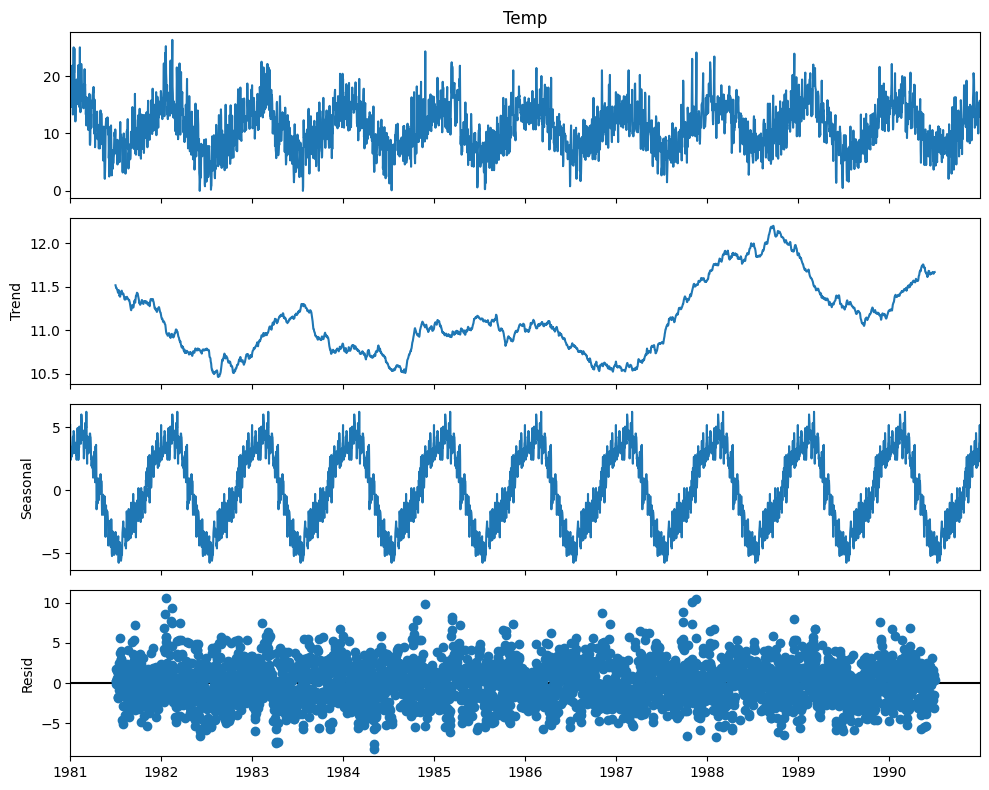

Variance share -> seasonal: 57.8% | trend: 1.0% | residual: 39.0%
Seasonal amplitude (max-min): 11.98 C
Trend range: 10.46 to 12.20 C
Residual mean: 0.001 | std: 2.543


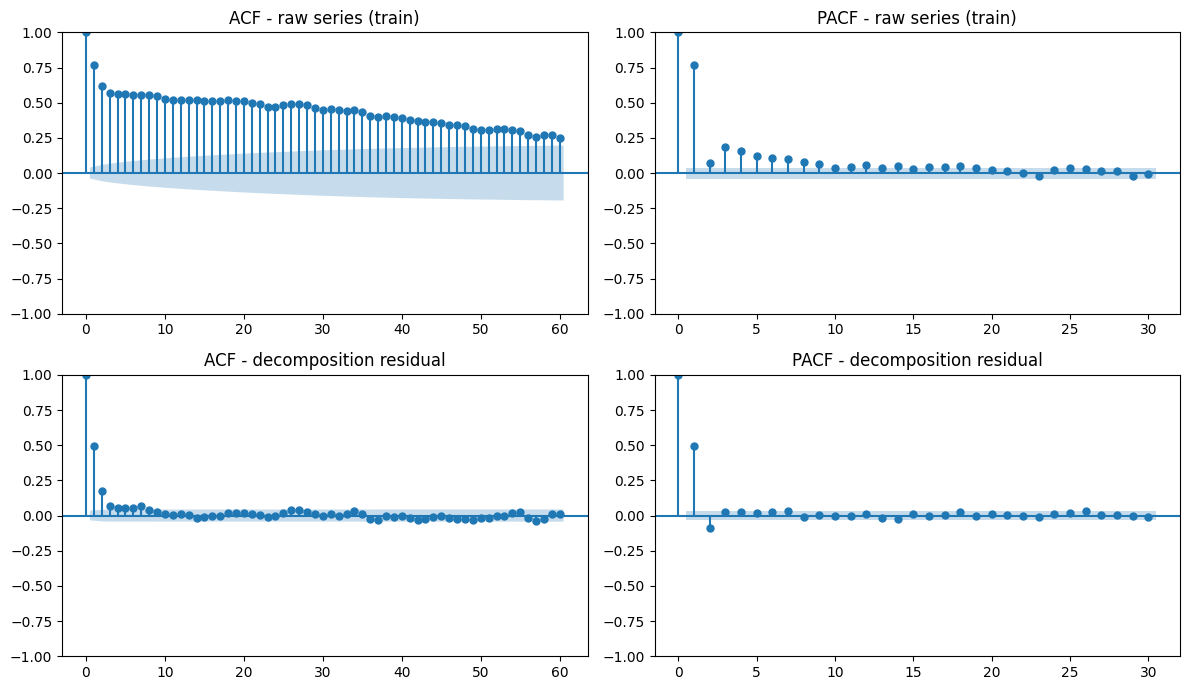

Raw ACF at lags 1,2,3,7,30,180,365: [ 0.765  0.616  0.57   0.556  0.451 -0.444  0.457]
Residual ACF at lags 1,2,3,7: [0.496 0.177 0.071 0.065]


In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# --- Decomposition (additive, yearly period) ---
dec = seasonal_decompose(series, model="additive", period=365)
fig = dec.plot(); fig.set_size_inches(10, 8); plt.tight_layout(); plt.show()

tv = series.var()
print("Variance share -> seasonal: %.1f%% | trend: %.1f%% | residual: %.1f%%" % (
    100*dec.seasonal.var()/tv, 100*dec.trend.dropna().var()/tv, 100*dec.resid.dropna().var()/tv))
print("Seasonal amplitude (max-min): %.2f C" % (dec.seasonal.max() - dec.seasonal.min()))
print("Trend range: %.2f to %.2f C" % (dec.trend.min(), dec.trend.max()))
resid = dec.resid.dropna()
print("Residual mean: %.3f | std: %.3f" % (resid.mean(), resid.std()))

# --- ACF / PACF on TRAIN only (avoids peeking at val/test) ---
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(train, lags=60, ax=ax[0, 0], title="ACF - raw series (train)")
plot_pacf(train, lags=30, ax=ax[0, 1], method="ywm", title="PACF - raw series (train)")
plot_acf(resid, lags=60, ax=ax[1, 0], title="ACF - decomposition residual")
plot_pacf(resid, lags=30, ax=ax[1, 1], method="ywm", title="PACF - decomposition residual")
plt.tight_layout(); plt.show()

a = acf(train, nlags=400)
print("Raw ACF at lags 1,2,3,7,30,180,365:", np.round(a[[1, 2, 3, 7, 30, 180, 365]], 3))
ar = acf(resid, nlags=30)
print("Residual ACF at lags 1,2,3,7:", np.round(ar[[1, 2, 3, 7]], 3))

Raw (train)                  n=2556  ADF stat= -3.928 p=0.0018 -> stationary      | KPSS stat= 0.116 p=0.100 -> stationary
First difference d=1         n=2555  ADF stat=-18.445 p=0.0000 -> stationary      | KPSS stat= 0.296 p=0.100 -> stationary
Seasonal difference D=365    n=2191  ADF stat=-18.660 p=0.0000 -> stationary      | KPSS stat= 0.199 p=0.100 -> stationary
Seasonal + first diff        n=2190  ADF stat=-15.830 p=0.0000 -> stationary      | KPSS stat= 0.063 p=0.100 -> stationary


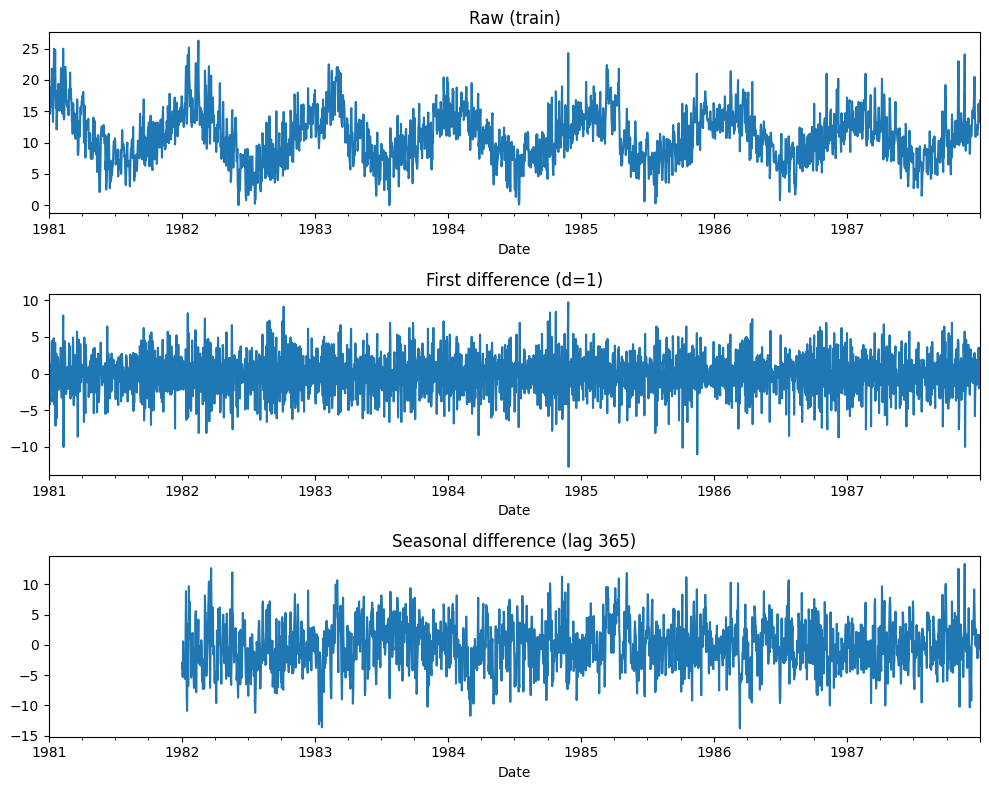

In [12]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
warnings.filterwarnings("ignore")  # KPSS p-value interpolation warnings

def stationarity_report(x, name):
    x = x.dropna()
    adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
    kp_stat, kp_p, *_ = kpss(x, regression="c", nlags="auto")
    adf_verdict = "stationary" if adf_p < 0.05 else "NON-stationary"
    kpss_verdict = "stationary" if kp_p >= 0.05 else "NON-stationary"
    print(f"{name:<28} n={len(x):<5} ADF stat={adf_stat:7.3f} p={adf_p:.4f} -> {adf_verdict:<15} | "
          f"KPSS stat={kp_stat:6.3f} p={kp_p:.3f} -> {kpss_verdict}")

# Tested on TRAIN only, to avoid peeking at val/test
stationarity_report(train, "Raw (train)")
stationarity_report(train.diff(1), "First difference d=1")
stationarity_report(train.diff(365), "Seasonal difference D=365")
stationarity_report(train.diff(365).diff(1), "Seasonal + first diff")

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=False)
train.plot(ax=ax[0], title="Raw (train)")
train.diff(1).plot(ax=ax[1], title="First difference (d=1)")
train.diff(365).plot(ax=ax[2], title="Seasonal difference (lag 365)")
plt.tight_layout(); plt.show()